# Mock maker interface

Run from `horizon/` using the `.venv/bin/python` kernel. The baseline is M1,
alpha = -0.075, N = 50, with table UV--X errors and SARM log scatter 0.30.

This notebook produces mock luminosity and angular diameter distances as measured
from quasars, and writes them as a paired dataset in natural-log error space.

Each catalogue is saved as three files:

* `<stem>_paired_dataset.npz` — the distances together with their **log** scatters
  `sigma_ln_dl`, `sigma_ln_da`. This is what the likelihood reads.
* `<stem>_metadata.json` — the configuration that produced it.
* `<stem>_diagnostic.png` — residual checks.

The log scatters are stored explicitly and never reconstructed from an absolute
error in Mpc. Dividing a stored sigma by a *measured* distance would fold each
object's own noise into its own weight, which biases alpha.


## Import packages

In [1]:
import json
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timezone
from pathlib import Path

plt.style.use('sanglier')

from tools.QSO_specifications import QSOSpecs
from tools.theory import angular_diameter_distance, ddr_eta
from tools.error_models import resolve_uvx_error, resolve_sarm_error
from tools.flux_error_models import load_flux_error_table, realize_flux_uncertainties
from tools.qso_mock import generate_paired_log_mock, save_paired_log_mock
from tools.mockchecker import save_paired_mock_diagnostic

## Set the observational specifications
Here we can set:
* `n_QSO`: the number of observed events (i.e. the size of our mock dataset).
* `z_min`, `z_max`: the minimum and maximum redshifts.

In [2]:
specs = {'n_QSO': 10000,
         'z_min': 0.2, #0.2,
         'z_max': 2.0#2.0
        }

## Set fiducial cosmology and DDR violation
Here we set $\Omega_m$ and $H_0$ and the model for the DDR violation in the luminosity distance.

The available options for `model` are:
#### M1
$\eta = 1 + \alpha$

#### M2
$\eta = 1 + \alpha + \beta z$

#### M3
$\eta = (1+z)^\alpha$

`beta` is used by M2 only.

In [3]:
cosmo = {'H0': 67.36,
         'Omegam': 0.314,
         'model': 'flat_lcdm'}

DDR = {'model': 'M1',
       'alpha': -0.075,
       'beta': -0.014}

## Set the error budget
`uvx` is the UV--X-ray luminosity-distance scatter, `sarm` the spectroastrometric
angular-distance scatter. Both take `'current'`, `'future'`, `'targeted'` or
`'custom'`; `gamma` is the slope of the UV--X-ray relation.

Alternatively, set `uvx='lusso2020_flux_table'` to use the Lusso flux-error
table. It combines redshift-dependent UV and X-ray measurement errors with
`delta_dex`, the intrinsic scatter in the log10 X-ray flux direction, and
propagates the result to each object's `sigma_ln_dl`. This replaces the
fixed UV--X tier; the two are not added together. SARM remains an independent
choice. The table supports redshifts from 0.05 to 7.5, without extrapolation.

`flux_measurement_error_correlation` correlates the signed UV and X-ray
measurement errors. It is distinct from the table's correlation between
uncertainty sizes, and from `rho` below.

`rho` correlates the two distances of the same object. The likelihood assumes
independent errors and will refuse a dataset with `rho != 0`.

Set `mode` to `'asimov'` for a noiseless catalogue, or `'random'` for a noise
realisation controlled by `seed`. Table mode uses median flux uncertainties
for an Asimov catalogue, or samples uncertainty sizes for a random catalogue.

In [4]:
errors = {'uvx': 'current', #'lusso2020_flux_table',
          'sarm': 'current',
          'gamma': 0.60,
          'rho': 0.0}

# Used only when uvx is 'lusso2020_flux_table'.
flux_errors = {'table': 'data/lusso2020_flux_error_model.csv',
               'delta_dex': 0.21,
               'flux_measurement_error_correlation': 0.0}

mode = 'asimov'
seed = 27

## Set where the mock data file will be saved
The directory is created if it does not already exist. The trailing scenario tag
is what `Utilities.list_mock_datasets` reads back as the `errors` column, so it is
kept whenever both budgets are the same named scenario. Table-based mocks
go in a separate subdirectory labelled by SARM option, mode and seed; the
sampler discovers these recursively. Change `outdir` to retain multiple
runs with different table settings but the same SARM option, mode and seed.

In [5]:
outdir = Path('mock_data')
if errors['uvx'] == 'lusso2020_flux_table':
    outdir = (outdir / 'lusso2020_flux_table' / f"{errors['sarm']}_sarm"
              / f"{mode}_seed{seed}")

tag  = f"_{errors['uvx']}" if errors['uvx'] == errors['sarm'] else ''
stem = (f"{DDR['model']}alpha{DDR['alpha']}"
        f"beta{DDR['beta']}nQSO{specs['n_QSO']}{tag}")
print(outdir / stem)

mock_data/lusso2020_flux_table/current_sarm/asimov_seed27/M1alpha-0.075beta-0.014nQSO10000


## Build the catalogue
Redshifts, distance noise and flux-uncertainty sizes use three independent
random streams. The first two retain their previous seeds, so using the
table does not reshuffle redshifts or standardised distance-noise draws.

In [6]:
sarm = resolve_sarm_error(errors['sarm'])

z_seed, noise_seed, flux_seed = np.random.SeedSequence(seed).spawn(3)

z   = QSOSpecs.redshift_distribution(specs, rng=np.random.default_rng(z_seed), mode=mode)
da  = angular_diameter_distance(z, cosmo['H0'], cosmo['Omegam'], cosmo['model'])
eta = ddr_eta(z, DDR['model'], DDR['alpha'], DDR['beta'])

flux_table = None
flux_uncertainties = None
sigma_uvx_dex = None
if errors['uvx'] == 'lusso2020_flux_table':
    flux_table = load_flux_error_table(flux_errors['table'])
    flux_uncertainties = realize_flux_uncertainties(
        flux_table, z,
        gamma=errors['gamma'],
        delta_dex=flux_errors['delta_dex'],
        flux_measurement_error_correlation=flux_errors['flux_measurement_error_correlation'],
        mode=mode,
        rng=np.random.default_rng(flux_seed),
    )
    sigma_ln_dl = flux_uncertainties.sigma_ln_dl
    errors_include_intrinsic = True
else:
    uvx = resolve_uvx_error(errors['uvx'], gamma=errors['gamma'])
    sigma_ln_dl = uvx.sigma_ln_dl
    sigma_uvx_dex = uvx.sigma_uvx_dex
    errors_include_intrinsic = uvx.errors_include_intrinsic

print(f"sigma_ln_dl: median {np.median(sigma_ln_dl):.3f}, "
      f"range [{np.min(sigma_ln_dl):.3f}, {np.max(sigma_ln_dl):.3f}]")
print(f"sigma_ln_da = {sarm.sigma_ln_da:.3f}")

mock = generate_paired_log_mock(
    z, da, eta,
    sigma_ln_dl, sarm.sigma_ln_da,
    rho=errors['rho'],
    mode=mode,
    rng=np.random.default_rng(noise_seed),
    errors_include_intrinsic=errors_include_intrinsic,
)

print(f"{len(mock.redshift)} quasars, z in "
      f"[{mock.redshift.min():.2f}, {mock.redshift.max():.2f}]")

sigma_ln_dl: median 0.611, range [0.606, 0.649]
sigma_ln_da = 0.300
10000 quasars, z in [0.20, 2.00]


## Save the mock
In table mode the NPZ also stores each object's flux uncertainties and the
measurement/intrinsic components. The JSON records the table path, checksum
and provenance, along with the propagation settings.

In [7]:
outdir.mkdir(parents=True, exist_ok=True)

save_paired_log_mock(outdir / f"{stem}_paired_dataset.npz", mock,
                     flux_uncertainties=flux_uncertainties)

metadata = {
    'generated_at_utc': datetime.now(timezone.utc).isoformat(),
    'distance_unit': 'Mpc',
    'error_unit': 'natural-log distance standard deviation',
    'specifications': specs,
    'cosmology': cosmo,
    'ddr': DDR,
    'errors': {
        'uvx_option': errors['uvx'],
        'sigma_ln_dl': np.asarray(sigma_ln_dl).tolist(),
        'sigma_uvx_dex': sigma_uvx_dex,
        'gamma': errors['gamma'],
        'sarm_option': sarm.option,
        'sigma_ln_da': sarm.sigma_ln_da,
        'rho': errors['rho'],
        'errors_include_intrinsic': errors_include_intrinsic,
    },
    'mock_mode': mode,
    'random_seed': seed,
}
if flux_uncertainties is not None:
    metadata['errors']['flux_errors'] = {
        'model': flux_uncertainties.model_name,
        'delta_dex': flux_uncertainties.delta_dex,
        'flux_measurement_error_correlation': flux_uncertainties.flux_measurement_error_correlation,
        'table_path': str(flux_table.csv_path),
        'table_sha256': flux_table.csv_sha256,
        'table_provenance': dict(flux_table.provenance),
        'realization': 'median' if mode == 'asimov' else 'sampled',
    }
(outdir / f"{stem}_metadata.json").write_text(json.dumps(metadata, indent=2))

save_paired_mock_diagnostic(outdir / f"{stem}_diagnostic.png", mock, title=stem)

print('Sampler mock_file:', outdir / f"{stem}_paired_dataset.npz")

Sampler mock_file: mock_data/lusso2020_flux_table/current_sarm/asimov_seed27/M1alpha-0.075beta-0.014nQSO10000_paired_dataset.npz


## Plot the mock data
Error bars are asymmetric because the scatter is Gaussian in the log of the
distance, not in the distance itself.

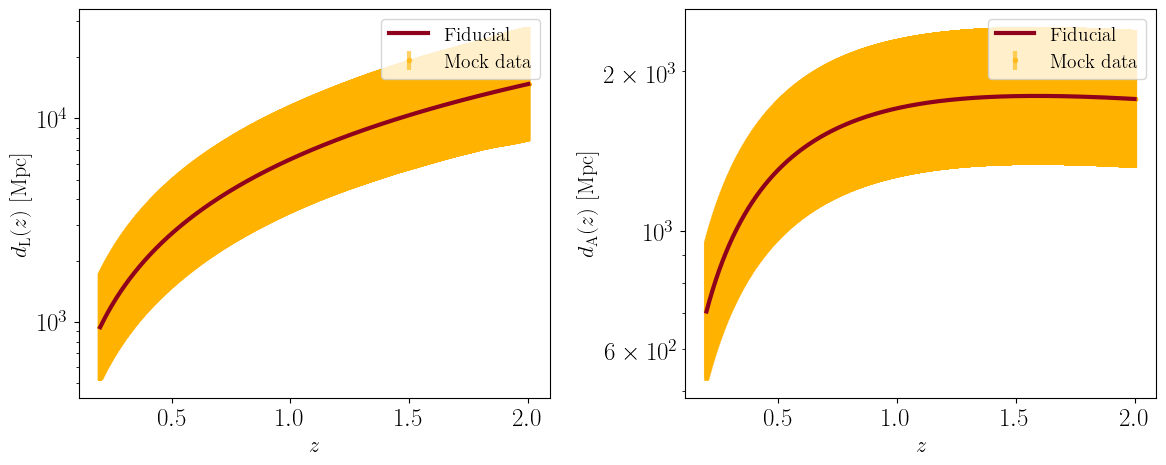

In [8]:
def log_bars(distance, sigma_ln):
    return np.vstack((distance * (1.0 - np.exp(-sigma_ln)),
                      distance * (np.exp(sigma_ln) - 1.0)))

order = np.argsort(mock.redshift)
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

for axis, obs, true, sig, label in (
    (ax[0], mock.dl_observed, mock.dl_true, mock.sigma_ln_dl, r'$d_{\rm L}(z)$ [Mpc]'),
    (ax[1], mock.da_observed, mock.da_true, mock.sigma_ln_da, r'$d_{\rm A}(z)$ [Mpc]'),
):
    axis.errorbar(mock.redshift, obs, yerr=log_bars(obs, sig),
                  ls='', marker='.', color='#FFB300', alpha=0.6,
                  label='Mock data', zorder=0)
    axis.plot(mock.redshift[order], true[order], color='#8E001C', lw=3,
              label='Fiducial', zorder=10)
    axis.set_xlabel(r'$z$', fontsize=16)
    axis.set_ylabel(label, fontsize=16)
    axis.set_yscale('log')
    axis.legend(loc='best', fontsize=14)

plt.tight_layout()
plt.show()

### Statistical checks
The residuals are Gaussian in log space, so this is where they should look normal.

ln dL standardised residuals: mean +0.000, sd 0.000
ln dA standardised residuals: mean +0.000, sd 0.000


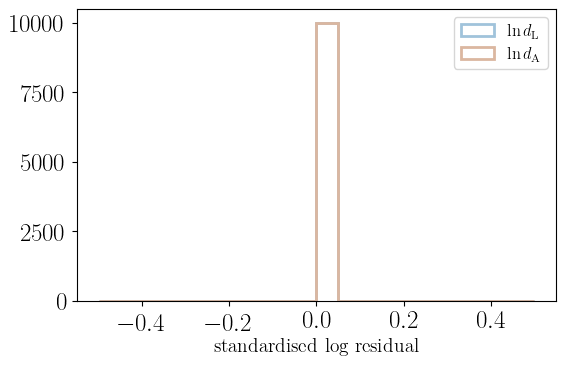

In [9]:
dl_res = np.log(mock.dl_observed / mock.dl_true) / mock.sigma_ln_dl
da_res = np.log(mock.da_observed / mock.da_true) / mock.sigma_ln_da

for name, r in (('ln dL', dl_res), ('ln dA', da_res)):
    print(f"{name} standardised residuals: mean {r.mean():+.3f}, sd {r.std():.3f}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(dl_res, bins=20, histtype='step', lw=2, label=r'$\ln d_{\rm L}$')
ax.hist(da_res, bins=20, histtype='step', lw=2, label=r'$\ln d_{\rm A}$')
ax.set_xlabel('standardised log residual', fontsize=14)
ax.legend(fontsize=12)
plt.tight_layout()
plt.show()

## Sample size needed to detect M1
In M1 every quasar measures the same $\ln\eta = \ln(1+\alpha_0)$ with scatter
$\sigma_{\ln\eta}$, so the uncertainty on $\alpha_0$ shrinks as
$\sigma_{\ln\eta}/\sqrt{N}$. This prints, as a LaTeX table, the number of quasars
needed to distinguish the M1 value of Teixeira et al. (2025, Table II),
$\alpha_0 = -0.075$, from zero at `significance` sigma in each error scenario.
No mock is needed.

In [ ]:
from tools.forecast import required_sample_grid

alpha0 = -0.075
significance = 3.0

rows = []
for scenario in ['current', 'future', 'targeted']:
    sigma_ln_dl = resolve_uvx_error(scenario, gamma=errors['gamma']).sigma_ln_dl
    sigma_ln_da = resolve_sarm_error(scenario).sigma_ln_da
    n_required = required_sample_grid(1 + alpha0, [sigma_ln_dl], [sigma_ln_da],
                                      significance)[0, 0]
    rows.append(f"        {scenario.capitalize()} & {n_required:.0f} \\\\")

print('\n'.join([
    r'\begin{table}',
    r'    \centering',
    r'    \begin{tabular}{lc}',
    r'        \hline',
    rf'        Scenario & $N_{{{significance:.0f}\sigma}}$ \\',
    r'        \hline',
    *rows,
    r'        \hline',
    r'    \end{tabular}',
    rf'    \caption{{Number of quasars required to distinguish $\alpha_0={alpha0}$ (M1) from zero at {significance:.0f}$\sigma$ in each error scenario.}}',
    r'    \label{tab:M1_N}',
    r'\end{table}',
]))

## Sample size needed to detect redshift evolution in M2
Number of quasars needed to detect $\alpha_1 \neq 0$ at `significance` sigma,
marginalising over $\alpha_0$, for the M2 values of Teixeira et al. (2025, Table II),
$\alpha_0 = -0.070$ and $\alpha_1 = -0.014$. This uses the Fisher matrix of the
$\ln\eta$ likelihood over the Asimov redshift distribution, so no mock is needed;
$\sigma(\alpha_1)$ at $N = 1000$ is printed as a check against the MCMC chains.

In [4]:
alpha0, alpha1 = -0.070, -0.014
significance = 3.0

# Expected Fisher matrix per quasar for sigma_ln_eta = 1, averaged over the
# Asimov redshift distribution of the mocks.
z_grid = QSOSpecs.redshift_distribution({**specs, 'n_QSO': 100000}, mode='asimov')
eta = ddr_eta(z_grid, 'M2', alpha0, alpha1)
gradient = np.vstack([np.ones_like(z_grid), z_grid]) / eta  # d ln(eta) / d(alpha0, alpha1)
fisher_per_quasar = gradient @ gradient.T / z_grid.size
sigma_alpha1_unit = np.sqrt(np.linalg.inv(fisher_per_quasar)[1, 1])  # marginalised over alpha0

for scenario in ['current', 'future', 'targeted']:
    sigma_ln_eta = np.hypot(resolve_uvx_error(scenario, gamma=errors['gamma']).sigma_ln_dl,
                            resolve_sarm_error(scenario).sigma_ln_da)
    sigma_alpha1 = sigma_ln_eta * sigma_alpha1_unit  # for N = 1
    n_required = np.ceil((significance * sigma_alpha1 / abs(alpha1))**2)
    print(f"{scenario.capitalize():9s}  sigma(alpha1) at N = 1000: {sigma_alpha1 / np.sqrt(1000):.3f}   "
          f"N for alpha1 != 0 at {significance:.0f} sigma: {n_required:.0f}")

Current    sigma(alpha1) at N = 1000: 0.042   N for alpha1 != 0 at 3 sigma: 80679
Future     sigma(alpha1) at N = 1000: 0.029   N for alpha1 != 0 at 3 sigma: 39747
Targeted   sigma(alpha1) at N = 1000: 0.024   N for alpha1 != 0 at 3 sigma: 26298
